# E1 (RQ1). Does the spatial context improve the quality and the predictive capacity of the phenotypes?

Configurations: global mining without context (baseline), global mining with context, and mining per unit.

It requires `Experiments/subgroups/mine_subgroups.py` (candidate subgroups) and, in `Experiments/phenotypes`, `mine_phenotypes.py` (DSLM algorithm of the subgroups library), `select_best_model.ipynb` and `cross_validation.py`.

Outputs: `results/tables/` and `results/figures/`.

In [1]:
import sys
sys.path.insert(0, "..")
import utils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from scipy.stats import wilcoxon

In [2]:
view = "clinical"
df = utils.read_mining_view(view)
# Best hyperparameters of each configuration (Experiments/phenotypes/results/clinical/best_models.csv).
best_models = pd.read_csv(utils.best_models_path(view)).set_index("configuration")

def best_subgroup_lists(configuration):
    # Output file of DSLM (subgroups library) with the best hyperparameters.
    return utils.read_subgroup_lists(utils.best_subgroup_lists_path(view, best_models, configuration))

TABLES_PATH = utils.results_path("E1-context-and-quality", "tables")
FIGURES_PATH = utils.results_path("E1-context-and-quality", "figures")
best_models

,beta,maximum_positive_overlap,maximum_negative_overlap,quality,coverage,diversity,number_of_subgroups
configuration,,,,,,,
without_context,0.75,0.6,0.6,0.126334,0.746108,0.738095,14
with_context,0.75,0.6,0.6,0.120226,0.694212,0.611111,16
unit_MICU,0.30,0.6,0.6,0.093467,0.879617,0.766667,5
unit_SICU,1.00,0.1,0.1,0.068543,0.503546,0.722222,4
unit_TSICU,0.00,0.1,0.1,0.025262,0.401674,1.000000,1
unit_CCU,0.00,0.1,0.1,0.022783,0.264423,1.000000,1
unit_CSRU,0.00,0.1,0.1,0.042283,0.468966,1.000000,1
unit_NO_ICU,0.00,0.1,0.1,0.055878,0.471673,1.000000,3


# 1. Quality of the phenotypes (full dataset)

The WRAcc of the per-unit lists is computed with the instances of each unit. The row 'per_unit (weighted)' is the mean of the units weighted by their number of instances.

In [3]:
rows = []
for configuration in utils.CONFIGURATIONS:
    dataset = utils.get_configuration_dataset(df, configuration).reset_index(drop=True)
    measures = utils.subgroup_lists_quality(dataset, best_subgroup_lists(configuration))
    measures["configuration"] = configuration
    measures["instances"] = len(dataset)
    measures["base_rate"] = utils.get_target_mask(dataset).mean()
    rows.append(measures)
quality_table = pd.DataFrame(rows).set_index("configuration")
units = quality_table.loc[["unit_" + u for u in utils.UNITS]]
weights = units["instances"] / units["instances"].sum()
quality_table.loc["per_unit (weighted)"] = (units.drop(columns=["number_of_lists"]).multiply(weights, axis=0)).sum()
quality_table.loc["per_unit (weighted)", "instances"] = units["instances"].sum()
quality_table.to_csv(TABLES_PATH / "quality_of_the_phenotypes.csv")
quality_table.round(3)

,number_of_lists,number_of_subgroups,mean_subgroups_per_list,quality,coverage,diversity,context_proportion,instances,base_rate
configuration,,,,,,,,,
without_context,3.0,14.00,4.667,0.126,0.746,0.738,0.000,2505.0,0.331
with_context,3.0,16.00,5.333,0.120,0.694,0.611,0.562,2505.0,0.331
unit_MICU,3.0,5.00,1.667,0.093,0.880,0.767,0.000,731.0,0.431
unit_SICU,3.0,4.00,1.333,0.069,0.504,0.722,0.000,423.0,0.357
unit_TSICU,3.0,1.00,0.333,0.025,0.402,1.000,0.000,239.0,0.218
unit_CCU,3.0,1.00,0.333,0.023,0.264,1.000,0.000,208.0,0.178
unit_CSRU,3.0,1.00,0.333,0.042,0.469,1.000,0.000,145.0,0.421
unit_NO_ICU,3.0,3.00,1.000,0.056,0.472,1.000,0.000,759.0,0.281
per_unit (weighted),NaN,3.28,1.093,0.063,0.572,0.885,0.000,2505.0,0.331


# 2. Phenotypes of the global configurations

In [4]:
rows = []
for configuration in utils.CONFIGURATIONS:
    dataset = utils.get_configuration_dataset(df, configuration).reset_index(drop=True)
    y = utils.get_target_mask(dataset)
    for index, subgroup_list in enumerate(best_subgroup_lists(configuration)):
        remaining = np.ones(len(dataset), dtype=bool)
        for position, description in enumerate(subgroup_list):
            covered = utils.covers(dataset, description)
            in_position = covered & remaining
            remaining &= ~covered
            rows.append({"configuration" : configuration, "list" : index + 1, "position" : position + 1, "subgroup" : utils.description_to_str(description),
                         "n" : int(covered.sum()), "precision" : y[covered].mean(), "wracc" : utils.wracc(dataset, description),
                         "n_in_position" : int(in_position.sum()), "precision_in_position" : y[in_position].mean() if in_position.sum() else np.nan})
        rows.append({"configuration" : configuration, "list" : index + 1, "position" : len(subgroup_list) + 1, "subgroup" : "default rule",
                     "n" : int(remaining.sum()), "precision" : y[remaining].mean() if remaining.sum() else np.nan, "wracc" : np.nan,
                     "n_in_position" : int(remaining.sum()), "precision_in_position" : y[remaining].mean() if remaining.sum() else np.nan})
phenotypes_table = pd.DataFrame(rows)
phenotypes_table.to_csv(TABLES_PATH / "phenotypes_of_all_the_configurations.csv", index=False)

In [5]:
for configuration in ["without_context", "with_context"]:
    dataset = utils.get_configuration_dataset(df, configuration).reset_index(drop=True)
    y = utils.get_target_mask(dataset)
    print("#################### " + configuration + " ####################")
    for index, subgroup_list in enumerate(best_subgroup_lists(configuration)):
        print("## Subgroup list " + str(index + 1) + " ##")
        remaining = np.ones(len(dataset), dtype=bool)
        for position, description in enumerate(subgroup_list):
            covered = utils.covers(dataset, description)
            in_position = covered & remaining
            remaining &= ~covered
            print("  s" + str(position + 1) + ": " + utils.description_to_str(description))
            print("      individually: n = " + str(covered.sum()) + ", %R = " + str(round(y[covered].mean(), 3)) + " | in its position: n = " + str(in_position.sum()) + ", %R = " + str(round(y[in_position].mean(), 3) if in_position.sum() else "-"))
        print("  default rule: n = " + str(remaining.sum()) + ", %R = " + str(round(y[remaining].mean(), 3)))
    print()

#################### without_context ####################
## Subgroup list 1 ##
  s1: [treated_with_vancomycin_in_previous_admissions = 'yes', treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
      individually: n = 267, %R = 0.727 | in its position: n = 267, %R = 0.727
  s2: [admission_location = 'TRANSFER_FROM_HOSPITAL', readmission = 'no', treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
      individually: n = 168, %R = 0.613 | in its position: n = 168, %R = 0.613
  s3: [admission_location = 'REFERRAL', treated_with_vancomycin_in_the_current_admission_before_culture = 'yes']
      individually: n = 340, %R = 0.585 | in its position: n = 247, %R = 0.534
  s4: [admission_location = 'REFERRAL', previous_isolation_of_sarm = 'no']
      individually: n = 738, %R = 0.367 | in its position: n = 412, %R = 0.192
  default rule: n = 1411, %R = 0.227
## Subgroup list 2 ##
  s1: [previous_exposure_to_antifungal_agents = 'yes', previous_exposure_t

# 3. Predictive capacity (stratified 10-fold cross-validation grouped by patient)

The subgroup lists are used as probabilistic classifiers (see `utils.SubgroupListClassifier`). 'per_unit' scores each test instance with the lists of its unit.

In [6]:
predictions = pd.read_csv(utils.cross_validation_path(view) / "predictions.csv")
scores = ["score_without_context", "score_with_context", "score_per_unit"]
rows = []
for fold, group in predictions.groupby("fold"):
    for score in scores:
        rows.append({"fold" : fold, "model" : score.replace("score_", ""), "auc_roc" : roc_auc_score(group["y"], group[score]), "auc_pr" : average_precision_score(group["y"], group[score])})
fold_metrics = pd.DataFrame(rows)
fold_metrics.to_csv(TABLES_PATH / "cv_auc_by_fold.csv", index=False)
cv_summary = fold_metrics.groupby("model")[["auc_roc", "auc_pr"]].agg(["mean", "std"])
cv_summary.to_csv(TABLES_PATH / "cv_auc_summary.csv")
cv_summary.round(3)

auc_roc        auc_pr       
                   mean    std   mean    std
model                                       
per_unit          0.718  0.051  0.557  0.058
with_context      0.721  0.038  0.574  0.047
without_context   0.733  0.032  0.566  0.041

In [7]:
pivot = fold_metrics.pivot(index="fold", columns="model")
tests = []
for metric in ["auc_roc", "auc_pr"]:
    for a, b in [("with_context", "without_context"), ("per_unit", "without_context"), ("per_unit", "with_context")]:
        statistic, p_value = wilcoxon(pivot[(metric, a)], pivot[(metric, b)])
        tests.append({"metric" : metric, "model_a" : a, "model_b" : b, "mean_difference" : (pivot[(metric, a)] - pivot[(metric, b)]).mean(), "wilcoxon_statistic" : statistic, "p_value" : p_value})
        print(metric + ": " + a + " vs. " + b + " -> mean difference = " + str(round((pivot[(metric, a)] - pivot[(metric, b)]).mean(), 4)) + ", Wilcoxon p-value = " + str(round(p_value, 4)))
pd.DataFrame(tests).to_csv(TABLES_PATH / "cv_wilcoxon_tests.csv", index=False)

auc_roc: with_context vs. without_context -> mean difference = -0.0123, Wilcoxon p-value = 0.1934
auc_roc: per_unit vs. without_context -> mean difference = -0.0148, Wilcoxon p-value = 0.375
auc_roc: per_unit vs. with_context -> mean difference = -0.0025, Wilcoxon p-value = 1.0
auc_pr: with_context vs. without_context -> mean difference = 0.0082, Wilcoxon p-value = 0.3223
auc_pr: per_unit vs. without_context -> mean difference = -0.0084, Wilcoxon p-value = 0.3223
auc_pr: per_unit vs. with_context -> mean difference = -0.0166, Wilcoxon p-value = 0.3223


Pooled out-of-fold predictions with 95% bootstrap confidence intervals (1000 resamples).

In [8]:
rng = np.random.default_rng(utils.RANDOM_SEED)
rows = []
for score in scores:
    y, s = predictions["y"].values, predictions[score].values
    auc_roc, auc_pr = roc_auc_score(y, s), average_precision_score(y, s)
    boot_roc, boot_pr = [], []
    for _ in range(1000):
        index = rng.integers(0, len(y), len(y))
        boot_roc.append(roc_auc_score(y[index], s[index]))
        boot_pr.append(average_precision_score(y[index], s[index]))
    rows.append({"model" : score.replace("score_", ""), "auc_roc" : auc_roc, "auc_roc_ci" : np.percentile(boot_roc, [2.5, 97.5]).round(3), "auc_pr" : auc_pr, "auc_pr_ci" : np.percentile(boot_pr, [2.5, 97.5]).round(3)})
pooled_auc = pd.DataFrame(rows)
pooled_auc.to_csv(TABLES_PATH / "pooled_auc_bootstrap_ci.csv", index=False)
pooled_auc.round(3)

,model,auc_roc,auc_roc_ci,auc_pr,auc_pr_ci
0,without_context,0.730,"[0.708, 0.751]",0.569,"[0.534, 0.603]"
1,with_context,0.717,"[0.693, 0.739]",0.572,"[0.534, 0.607]"
2,per_unit,0.711,"[0.689, 0.733]",0.547,"[0.512, 0.587]"


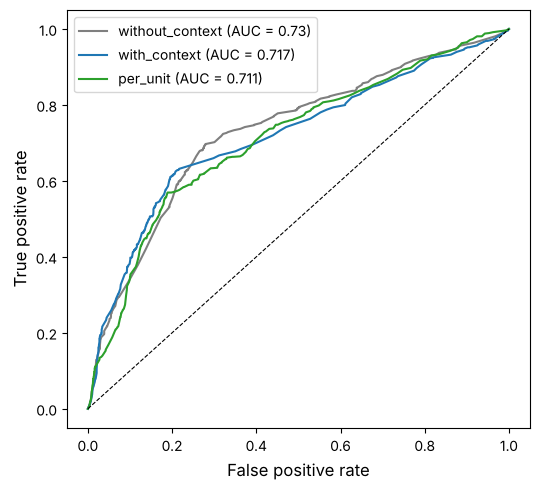

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for score, color in zip(scores, ["tab:gray", "tab:blue", "tab:green"]):
    fpr, tpr, _ = roc_curve(predictions["y"], predictions[score])
    ax.plot(fpr, tpr, color=color, label=score.replace("score_", "") + " (AUC = " + str(round(roc_auc_score(predictions["y"], predictions[score]), 3)) + ")")
ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
ax.set_xlabel("False positive rate", fontsize=12)
ax.set_ylabel("True positive rate", fontsize=12)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "roc_curves.pdf")
plt.show()

# 4. Predictive capacity inside each unit

In [10]:
rows = []
for unit, group in predictions.groupby("unit"):
    row = {"unit" : unit, "n" : len(group), "rate" : group["y"].mean()}
    for score in scores:
        row["auc_roc_" + score.replace("score_", "")] = roc_auc_score(group["y"], group[score]) if group["y"].nunique() == 2 else np.nan
    rows.append(row)
auc_by_unit = pd.DataFrame(rows)
auc_by_unit.to_csv(TABLES_PATH / "auc_by_unit.csv", index=False)
auc_by_unit.round(3)

,unit,n,rate,auc_roc_without_context,auc_roc_with_context,auc_roc_per_unit
0,CCU,208,0.178,0.748,0.705,0.651
1,CSRU,145,0.421,0.754,0.643,0.679
2,MICU,731,0.431,0.740,0.717,0.722
3,NO_ICU,759,0.281,0.649,0.652,0.679
4,SICU,423,0.357,0.772,0.770,0.712
5,TSICU,239,0.218,0.752,0.734,0.366
